# Neural Network for Y=AB+C

Epoch 0, Loss: 0.910536
Epoch 500, Loss: 0.125639
Epoch 1000, Loss: 0.103646
Epoch 1500, Loss: 0.077822
Epoch 2000, Loss: 0.056630
Epoch 2500, Loss: 0.043539
Epoch 3000, Loss: 0.035783
Epoch 3500, Loss: 0.029997
Epoch 4000, Loss: 0.024391
Epoch 4500, Loss: 0.018702


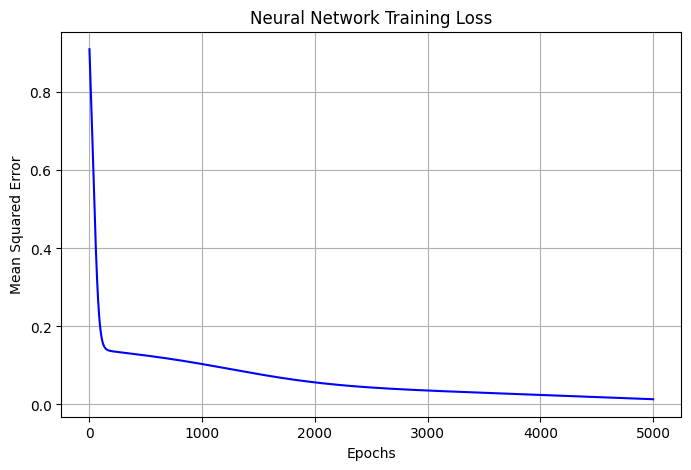

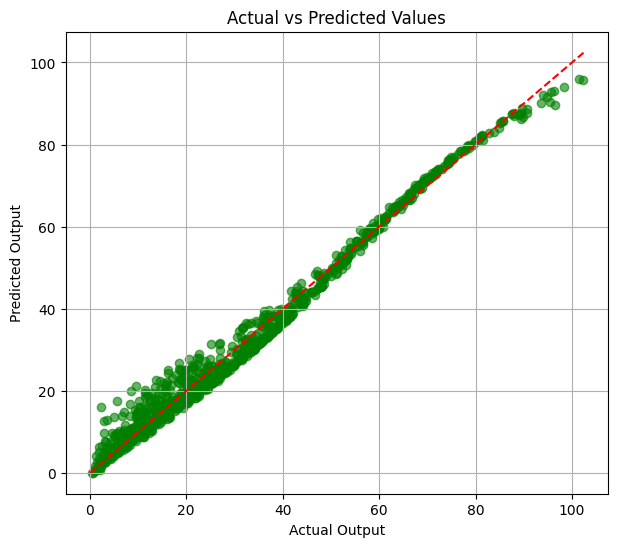

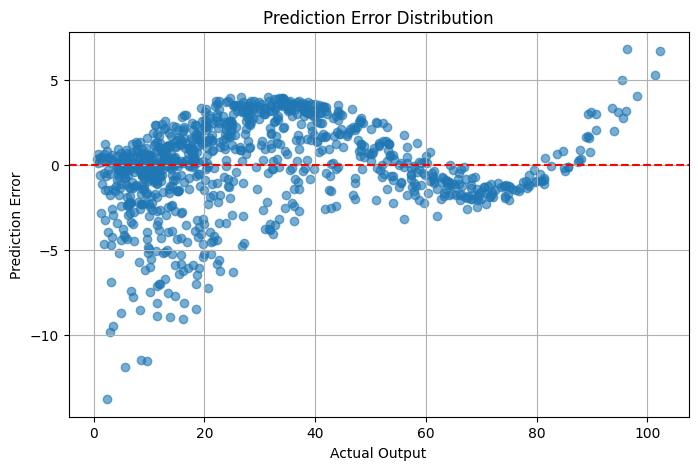


Test Results:
a=2, b=3, c=4 | Actual=10.00, Predicted=9.21
a=5, b=2, c=1 | Actual=11.00, Predicted=10.45
a=3, b=4, c=2 | Actual=14.00, Predicted=11.70


In [3]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
N = 1000
a = np.random.uniform(0, 10, N)
b = np.random.uniform(0, 10, N)
c = np.random.uniform(0, 10, N)
y = a * b + c
X = np.column_stack((a, b, c))
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
y_mean = y.mean()
y_std = y.std()
X = (X - X_mean) / X_std
Y = ((y - y_mean) / y_std).reshape(-1, 1)
input_size = 3
hidden_size = 16
output_size = 1
W1 = np.random.randn(input_size, hidden_size) * 0.1
B1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size) * 0.1
B2 = np.zeros((1, output_size))
learning_rate = 0.01
epochs = 5000
loss_history = []
for epoch in range(epochs):
    # Forward propgation
    Z1 = X @ W1 + B1
    A1 = np.tanh(Z1)
    Z2 = A1 @ W2 + B2
    Y_pred = Z2
    # Mean squared error
    loss = np.mean((Y_pred - Y) ** 2)
    loss_history.append(loss)
    # Backpropagation
    dZ2 = 2 * (Y_pred - Y) / N
    dW2 = A1.T @ dZ2
    dB2 = np.sum(dZ2, axis=0, keepdims=True)
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (1 - A1 ** 2)
    dW1 = X.T @ dZ1
    dB1 = np.sum(dZ1, axis=0, keepdims=True)
    W2 -= learning_rate * dW2
    B2 -= learning_rate * dB2
    W1 -= learning_rate * dW1
    B1 -= learning_rate * dB1
    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.6f}")
Y_pred = np.tanh(X @ W1 + B1) @ W2 + B2
y_pred = Y_pred.flatten() * y_std + y_mean
plt.figure(figsize=(8, 5))
plt.plot(loss_history, color='blue')
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.title("Neural Network Training Loss")
plt.grid(True)
plt.show()
plt.figure(figsize=(7, 6))
plt.scatter(y, y_pred, alpha=0.6, color='green')
minimum = min(y.min(), y_pred.min())
maximum = max(y.max(), y_pred.max())
plt.plot([minimum, maximum],
         [minimum, maximum], 'r--')
plt.xlabel("Actual Output")
plt.ylabel("Predicted Output")
plt.title("Actual vs Predicted Values")
plt.grid(True)
plt.show()
error = y - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y, error, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Actual Output")
plt.ylabel("Prediction Error")
plt.title("Prediction Error Distribution")
plt.grid(True)
plt.show()
test = np.array([[2, 3, 4],
                 [5, 2, 1],
                 [3, 4, 2]])
test_normalized = (test - X_mean) / X_std
test_hidden = np.tanh(test_normalized @ W1 + B1)
test_output = test_hidden @ W2 + B2
predictions = test_output.flatten() * y_std + y_mean
print("\nTest Results:")
for i in range(len(test)):
    actual = test[i, 0] * test[i, 1] + test[i, 2]
    print(
        f"a={test[i,0]}, b={test[i,1]}, c={test[i,2]} | "
        f"Actual={actual:.2f}, Predicted={predictions[i]:.2f}"
    )